In [1]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib as mpl

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("[INFO] Môi trường đã sẵn sàng!")

TensorFlow version: 2.21.0
OpenCV version: 4.14.0
NumPy version: 2.4.6
[INFO] Môi trường đã sẵn sàng!


In [2]:
import os
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.preprocessing import LabelBinarizer
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# 1. Định nghĩa các đường dẫn và tham số ban đầu
DIRECTORY = r"dataset"
CATEGORIES = ["with_mask", "without_mask"]

data = []
labels = []

print("[INFO] Đang nạp và xử lý tập ảnh...")

# 2. Vòng lặp duyệt qua từng thư mục ảnh
for category in CATEGORIES:
    path = os.path.join(DIRECTORY, category)
    for img_name in os.listdir(path):
        img_path = os.path.join(path, img_name)
        
        # Bỏ qua nếu có file ẩn/file rác không phải ảnh
        if not (img_name.endswith('.jpg') or img_name.endswith('.jpeg') or img_name.endswith('.png')):
            continue

        # Load ảnh và resize về chuẩn 224x224 (kích thước đầu vào chuẩn của MobileNetV2)
        image = load_img(img_path, target_size=(224, 224))
        image = img_to_array(image)
        
        # Chuẩn hóa giá trị pixel ảnh phù hợp với yêu cầu của MobileNetV2 (-1 đến 1)
        image = preprocess_input(image)

        data.append(image)
        labels.append(category)

# 3. Chuyển đổi dữ liệu sang dạng NumPy array
data = np.array(data, dtype="float32")
labels = np.array(labels)

# 4. Mã hóa nhãn (One-Hot Encoding): with_mask -> [1, 0], without_mask -> [0, 1]
lb = LabelBinarizer()
labels = lb.fit_transform(labels)
labels = to_categorical(labels)

# 5. Phân chia tập dữ liệu: 80% để huấn luyện (Train), 20% để kiểm thử (Test)
(trainX, testX, trainY, testY) = train_test_split(
    data, labels, test_size=0.20, stratify=labels, random_state=42
)

print(f"[INFO] Tổng số ảnh đã xử lý: {len(data)}")
print(f"[INFO] Kích thước tập Train (trainX): {trainX.shape}")
print(f"[INFO] Kích thước tập Test (testX): {testX.shape}")

[INFO] Đang nạp và xử lý tập ảnh...


d:\MaskDetecter\venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


[INFO] Tổng số ảnh đã xử lý: 4086
[INFO] Kích thước tập Train (trainX): (3268, 224, 224, 3)
[INFO] Kích thước tập Test (testX): (818, 224, 224, 3)


In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import AveragePooling2D, Dropout, Flatten, Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# 1. Cấu hình Data Augmentation (Tăng cường dữ liệu)
aug = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

# 2. Tải kiến trúc MobileNetV2 (Transfer Learning)
baseModel = MobileNetV2(weights="imagenet", include_top=False, input_tensor=Input(shape=(224, 224, 3)))

# 3. Xây dựng phần đầu phân loại (Classification Head)
headModel = baseModel.output
headModel = AveragePooling2D(pool_size=(7, 7))(headModel)
headModel = Flatten(name="flatten")(headModel)
headModel = Dense(128, activation="relu")(headModel)
headModel = Dropout(0.5)(headModel)
headModel = Dense(2, activation="softmax")(headModel) # 2 lớp: có khẩu trang và không khẩu trang

# 4. Lắp ráp Base Model và Head Model
model = Model(inputs=baseModel.input, outputs=headModel)

# 5. Đóng băng (Freeze) các trọng số của Base Model
for layer in baseModel.layers:
    layer.trainable = False

# 6. Biên dịch mô hình
INIT_LR = 1e-4
EPOCHS = 20
BS = 32

print("[INFO] Đang biên dịch mô hình...")
opt = Adam(learning_rate=INIT_LR, decay=INIT_LR / EPOCHS)
model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["accuracy"])
print("[INFO] Biên dịch thành công. Khung mô hình đã sẵn sàng!")

C:\Users\Admin\AppData\Local\Temp\ipykernel_4628\3635788151.py:19: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  baseModel = MobileNetV2(weights="imagenet", include_top=False, input_tensor=Input(shape=(224, 224, 3)))


[INFO] Đang biên dịch mô hình...
[INFO] Biên dịch thành công. Khung mô hình đã sẵn sàng!


d:\MaskDetecter\venv\Lib\site-packages\keras\src\optimizers\base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


[INFO] Bắt đầu huấn luyện mạng neural (Training Head Model)...
Epoch 1/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 110s 1s/step - accuracy: 0.8591 - loss: 0.3987 - val_accuracy: 0.9756 - val_loss: 0.1608
Epoch 2/20
  1/102 ━━━━━━━━━━━━━━━━━━━━ 1:08 678ms/step - accuracy: 0.9688 - loss: 0.1905

d:\MaskDetecter\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


102/102 ━━━━━━━━━━━━━━━━━━━━ 18s 169ms/step - accuracy: 0.9688 - loss: 0.1905 - val_accuracy: 0.9756 - val_loss: 0.1595
Epoch 3/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.9608 - loss: 0.1567 - val_accuracy: 0.9731 - val_loss: 0.0945
Epoch 4/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 20s 196ms/step - accuracy: 1.0000 - loss: 0.0935 - val_accuracy: 0.9731 - val_loss: 0.0950
Epoch 5/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.9756 - loss: 0.1062 - val_accuracy: 0.9878 - val_loss: 0.0638
Epoch 6/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 17s 160ms/step - accuracy: 0.9688 - loss: 0.1126 - val_accuracy: 0.9890 - val_loss: 0.0636
Epoch 7/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.9774 - loss: 0.0847 - val_accuracy: 0.9890 - val_loss: 0.0540
Epoch 8/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 17s 159ms/step - accuracy: 1.0000 - loss: 0.0352 - val_accuracy: 0.9890 - val_loss: 0.0540
Epoch 9/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 91s 894ms/step - accuracy: 0.9790 - loss: 0.0661 - val_accur

[INFO] Đang lưu mô hình vào đĩa...
[INFO] Đã xuất file mô hình thành công: 'mask_detector.h5'


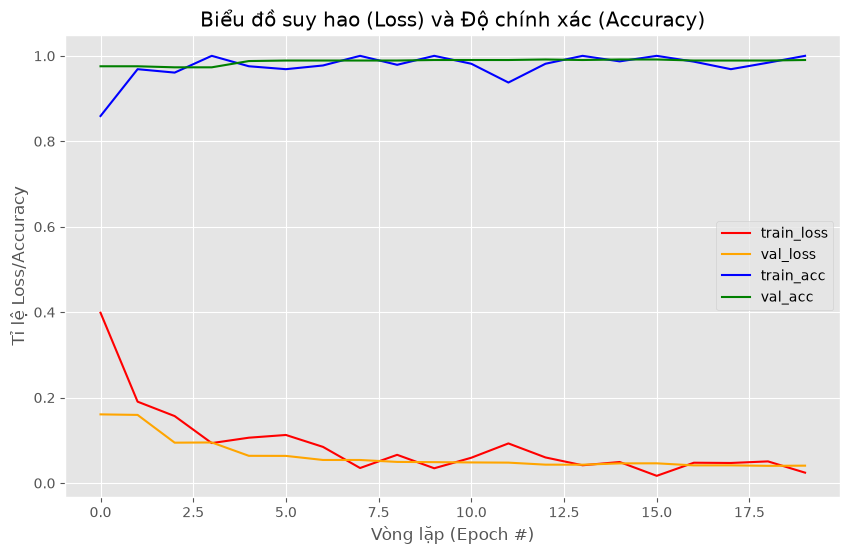

In [4]:
import matplotlib.pyplot as plt
import numpy as np

print("[INFO] Bắt đầu huấn luyện mạng neural (Training Head Model)...")
# Hàm model.fit sẽ liên tục nạp ảnh từ data generator vào mô hình để học đặc trưng
H = model.fit(
    aug.flow(trainX, trainY, batch_size=BS),
    steps_per_epoch=len(trainX) // BS,
    validation_data=(testX, testY),
    validation_steps=len(testX) // BS,
    epochs=EPOCHS
)

# Lưu lại toàn bộ kiến trúc và trọng số mô hình ra một file vật lý
print("[INFO] Đang lưu mô hình vào đĩa...")
model.save("mask_detector.h5", save_format="h5")
print("[INFO] Đã xuất file mô hình thành công: 'mask_detector.h5'")

# Trực quan hóa dữ liệu huấn luyện (Đánh giá chất lượng mô hình)
plt.style.use("ggplot")
plt.figure(figsize=(10, 6))
plt.plot(np.arange(0, EPOCHS), H.history["loss"], label="train_loss", color="red")
plt.plot(np.arange(0, EPOCHS), H.history["val_loss"], label="val_loss", color="orange")
plt.plot(np.arange(0, EPOCHS), H.history["accuracy"], label="train_acc", color="blue")
plt.plot(np.arange(0, EPOCHS), H.history["val_accuracy"], label="val_acc", color="green")
plt.title("Biểu đồ suy hao (Loss) và Độ chính xác (Accuracy)")
plt.xlabel("Vòng lặp (Epoch #)")
plt.ylabel("Tỉ lệ Loss/Accuracy")
plt.legend(loc="center right")
plt.savefig("training_plot.png")
plt.show()

In [2]:
import cv2
import numpy as np
import os
import urllib.request
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array

# 1. Tải mô hình MobileNetV2 vừa huấn luyện
print("[INFO] Đang tải mô hình phân loại khẩu trang...")
mask_model = load_model("mask_detector.h5")

# 2. Kiểm tra và tải file haarcascade_frontalface_default.xml nếu chưa có
xml_filename = "haarcascade_frontalface_default.xml"
xml_url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml"

if not os.path.exists(xml_filename):
    print(f"[INFO] Đang tải file {xml_filename} từ GitHub OpenCV...")
    urllib.request.urlretrieve(xml_url, xml_filename)
    print("[INFO] Tải thành công!")

# Nạp bộ phát hiện khuôn mặt từ file XML trong thư mục dự án
print("[INFO] Đang tải bộ phát hiện khuôn mặt...")
face_cascade = cv2.CascadeClassifier(xml_filename)

if face_cascade.empty():
    print("[LỖI] Không thể tải file haarcascade. Kiểm tra lại kết nối mạng hoặc file XML!")
else:
    print("[INFO] Đã nạp thành công bộ phát hiện khuôn mặt!")

# 3. Kích hoạt Webcam (Số 0 thường là webcam mặc định)
print("[INFO] Đang khởi động Webcam...")
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    if not ret:
        print("[LỖI] Không thể đọc được tín hiệu từ Webcam.")
        break
        
    # Lật ảnh lại như gương soi để dễ quan sát
    frame = cv2.flip(frame, 1)
    
    # Chuyển ảnh sang dạng đen trắng (Grayscale)
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    
    # Tìm các khuôn mặt trong khung hình
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))

    for (x, y, w, h) in faces:
        # Cắt khuôn mặt khỏi frame
        face_roi = frame[y:y+h, x:x+w]
        face_roi = cv2.cvtColor(face_roi, cv2.COLOR_BGR2RGB)
        
        # Tiền xử lý khuôn mặt về chuẩn (224x224)
        face_roi = cv2.resize(face_roi, (224, 224))
        face_roi = img_to_array(face_roi)
        face_roi = preprocess_input(face_roi)
        face_roi = np.expand_dims(face_roi, axis=0)

        # Dự đoán
        (mask, withoutMask) = mask_model.predict(face_roi, verbose=0)[0]

        # Xác định nhãn và màu sắc
        label = "Mask" if mask > withoutMask else "No Mask"
        color = (0, 255, 0) if label == "Mask" else (0, 0, 255)
        
        # In tỉ lệ phần trăm độ tin cậy
        label = "{}: {:.2f}%".format(label, max(mask, withoutMask) * 100)

        # Vẽ khung và label
        cv2.putText(frame, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)

    # Hiển thị cửa sổ
    cv2.imshow("He thong Nhan dien Khau trang - Nhan 'q' de thoat", frame)

    # Nhấn 'q' để thoát
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

[INFO] Đang tải mô hình phân loại khẩu trang...


[INFO] Đang tải bộ phát hiện khuôn mặt...
[INFO] Đã nạp thành công bộ phát hiện khuôn mặt!
[INFO] Đang khởi động Webcam...
